# Part 1 — Exploratory Data Analysis
Gas Turbine CO and NOx Emissions (UCI, 2011–2015)


## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap

from data_prep import FIG_DIR, PART1_DIR, VARIABLES, load_clean

# Palette
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#5598e7", "#104281"])
YEAR_COLORS = dict(zip(range(2011, 2016), [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})

## 2. Functions

In [2]:
STATS = []


def note(msg):
    STATS.append(msg)
    print(msg)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name)
    plt.show()


def binned_mean(x, y, bins=25):
    """Mean of x and y within quantile bins of x."""
    cut = pd.qcut(x, bins, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(cut, observed=True).mean()
    return g.x.values, g.y.values

## 3. Load cleaned data

In [3]:
df = load_clean()
note(f"Rows {len(df)}, columns {df.shape[1]}")
df.head()

Rows 36624, columns 13


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,year,row_in_year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011,0
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011,1
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011,2
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011,3
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011,4


## 4. Figure 1 — Emission distributions
NOx is moderately right-skewed; CO is heavily right-skewed.

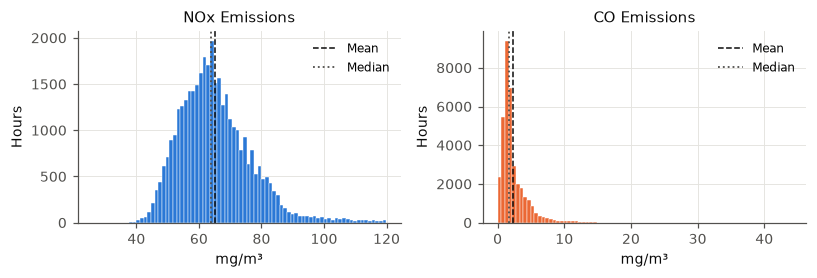

NOX: mean 65.31, median 63.88, sd 11.69, skew 1.02, P99 105.20, max 119.91
CO: mean 2.38, median 1.72, sd 2.26, skew 4.84, P99 11.01, max 44.10


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.6))
for ax, col, color, title in [(axes[0], "NOX", BLUE, "NOx Emissions"),
                              (axes[1], "CO", ORANGE, "CO Emissions")]:
    s = df[col]
    ax.hist(s, bins=80, color=color, edgecolor="white", linewidth=0.3)
    ax.axvline(s.mean(), color=INK, ls="--", lw=1, label="Mean")
    ax.axvline(s.median(), color=INK2, ls=":", lw=1.2, label="Median")
    ax.set(title=title, xlabel="mg/m³", ylabel="Hours")
    ax.legend(loc="upper right", fontsize=8)
save(fig, "fig1_hist_nox_co.png")

for col in ("NOX", "CO"):
    s = df[col]
    note(f"{col}: mean {s.mean():.2f}, median {s.median():.2f}, sd {s.std():.2f}, "
         f"skew {s.skew():.2f}, P99 {s.quantile(.99):.2f}, max {s.max():.2f}")

## 5. Figure 2 — NOx vs TIT
Linear fit plus a binned mean.

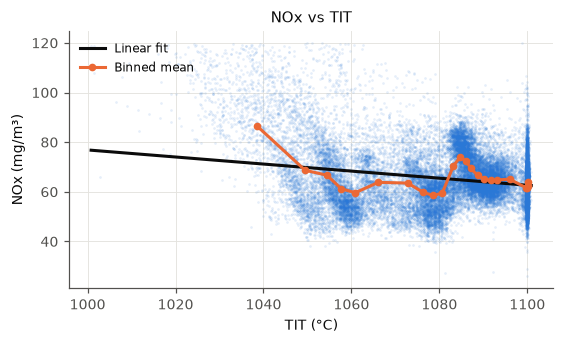

NOx~TIT linear: slope -0.1422, R2 0.0456, r -0.213
Binned mean NOx by TIT bin: 1039:86.5, 1049:68.7, 1054:66.7, 1058:61.2, 1061:59.7, 1066:63.8, 1073:63.5, 1076:59.8, 1079:58.6, 1081:59.4, 1083:70.4, 1085:74.1, 1086:72.5, 1087:69.5, 1089:66.6, 1090:65.1, 1092:64.6, 1093:64.8, 1096:65.1, 1100:61.7, 1100:61.5, 1100:61.8, 1100:62.5, 1100:64.1
TIT<1050 rows 2296 (6.3%); mean NOx 80.45 vs TIT>=1050 64.30


In [5]:
fit = sm.OLS(df.NOX, sm.add_constant(df.TIT)).fit()
b0, b1 = fit.params.iloc[0], fit.params.iloc[1]
bx, by = binned_mean(df.TIT, df.NOX)

fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.scatter(df.TIT, df.NOX, s=3, alpha=0.12, color=BLUE, linewidths=0, rasterized=True)
xs = np.linspace(df.TIT.min(), df.TIT.max(), 100)
ax.plot(xs, b0 + b1 * xs, color=INK, lw=2, label="Linear fit")
ax.plot(bx, by, color=ORANGE, lw=2, marker="o", ms=4, label="Binned mean")
ax.set(title="NOx vs TIT", xlabel="TIT (°C)", ylabel="NOx (mg/m³)")
ax.legend(loc="upper left", fontsize=8)
save(fig, "fig2_nox_vs_tit.png")

note(f"NOx~TIT linear: slope {b1:.4f}, R2 {fit.rsquared:.4f}, r {df.TIT.corr(df.NOX):.3f}")
note("Binned mean NOx by TIT bin: " + ", ".join(f"{x:.0f}:{y:.1f}" for x, y in zip(bx, by)))
low = df.TIT < 1050
note(f"TIT<1050 rows {low.sum()} ({low.mean():.1%}); mean NOx {df.NOX[low].mean():.2f} "
     f"vs TIT>=1050 {df.NOX[~low].mean():.2f}")

## 6. Figure 3 — CO vs NOx, coloured by load (TEY)
CO on a log scale; low-load hours are darkest and drawn on top.

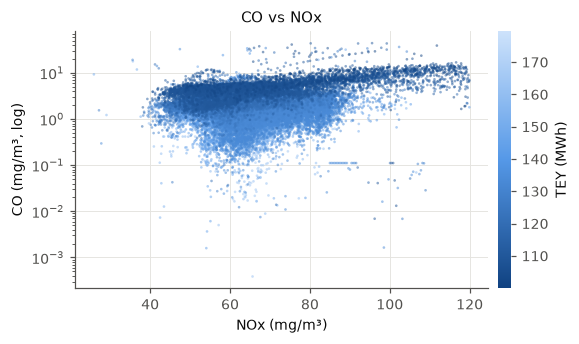

corr(CO,NOX) pearson 0.340, spearman 0.056
corr(TIT,CO) -0.706; corr(TEY,CO) -0.570
By TEY band (mean NOx, mean CO, mean TIT, n):
              NOx    CO      TIT      n
TEY                                    
(0, 110]    70.19  6.20  1047.90   3337
(110, 125]  65.25  3.82  1059.99   5967
(125, 135]  65.95  1.76  1084.65  15409
(135, 145]  65.62  1.66  1090.26   3021
(145, 160]  61.26  1.32  1099.63   6567
(160, 200]  65.27  1.16  1099.96   2323
Low load TEY<110: corr(CO,NOx) 0.638; TEY>=110: 0.225


In [6]:
order = df.sort_values("TEY", ascending=False)

fig, ax = plt.subplots(figsize=(5.4, 3.2))
sc = ax.scatter(order.NOX, order.CO, c=order.TEY, cmap=SEQUENTIAL.reversed(), s=3,
                alpha=0.5, linewidths=0, rasterized=True)
ax.set_yscale("log")
ax.set(title="CO vs NOx", xlabel="NOx (mg/m³)", ylabel="CO (mg/m³, log)")
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("TEY (MWh)")
cb.solids.set_alpha(1)
cb.outline.set_visible(False)
save(fig, "fig3_co_vs_nox.png")

note(f"corr(CO,NOX) pearson {df.CO.corr(df.NOX):.3f}, spearman {df.CO.corr(df.NOX, method='spearman'):.3f}")
note(f"corr(TIT,CO) {df.TIT.corr(df.CO):.3f}; corr(TEY,CO) {df.TEY.corr(df.CO):.3f}")
bands = pd.cut(df.TEY, [0, 110, 125, 135, 145, 160, 200])
note("By TEY band (mean NOx, mean CO, mean TIT, n):\n" +
     df.groupby(bands, observed=True).agg(NOx=("NOX", "mean"), CO=("CO", "mean"),
                                          TIT=("TIT", "mean"), n=("NOX", "size")).round(2).to_string())
lo = df.TEY < 110
note(f"Low load TEY<110: corr(CO,NOx) {df[lo].CO.corr(df[lo].NOX):.3f}; "
     f"TEY>=110: {df[~lo].CO.corr(df[~lo].NOX):.3f}")

## 7. Figure 4 — Correlation matrix
The process variables (GTEP, TIT, CDP, TEY) form one highly collinear load block.

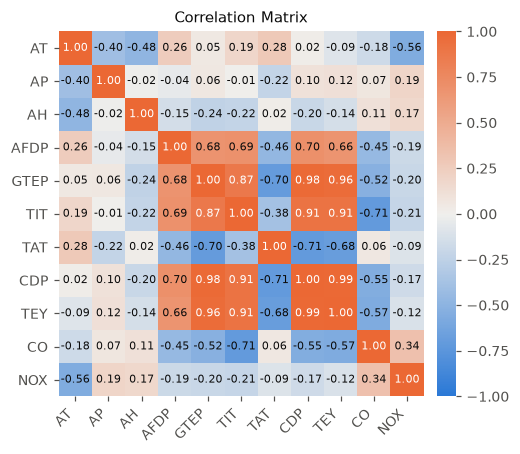

Correlation with NOX: AT     -0.561; TIT    -0.213; GTEP   -0.202; AFDP   -0.187; CDP    -0.171; TEY    -0.116; TAT    -0.094; AH      0.165; AP      0.194; CO      0.340
Strongest |r| pairs: CDP   TEY    0.989; GTEP  CDP    0.978;       TEY    0.964; TIT   TEY    0.910;       CDP    0.909; GTEP  TIT    0.874; TIT   CO     0.706; TAT   CDP    0.705


In [7]:
cols = list(VARIABLES)
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(5.0, 4.2))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.75 else INK)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cb.outline.set_visible(False)
ax.set_title("Correlation Matrix")
save(fig, "fig4_corr_heatmap.png")

note("Correlation with NOX: " + corr.NOX.drop("NOX").sort_values().round(3).to_string().replace("\n", "; "))
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
note("Strongest |r| pairs: " + pairs.abs().sort_values(ascending=False).head(8).round(3).to_string().replace("\n", "; "))

## 8. Figure 5 — NOx by ambient temperature

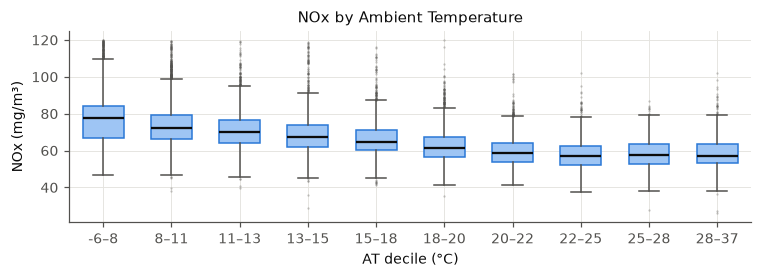

Median NOx by AT decile: 77.6, 72.5, 70.1, 67.6, 64.9, 61.6, 58.6, 57.3, 57.5, 57.1
corr(AT,NOX) -0.561; corr(AT,AH) -0.477


In [8]:
dec = pd.qcut(df.AT, 10)
groups = [g.NOX.values for _, g in df.groupby(dec, observed=True)]
labels = [f"{iv.left:.0f}–{iv.right:.0f}" for iv in dec.cat.categories]

fig, ax = plt.subplots(figsize=(7.0, 2.6))
bp = ax.boxplot(groups, patch_artist=True, widths=0.6,
                medianprops=dict(color=INK, lw=1.5),
                flierprops=dict(marker="o", ms=1.5, alpha=0.3, markeredgewidth=0, markerfacecolor=INK2),
                whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
for patch in bp["boxes"]:
    patch.set(facecolor="#9ec5f4", edgecolor=BLUE)
ax.set_xticks(range(1, 11), labels)
ax.set(title="NOx by Ambient Temperature", xlabel="AT decile (°C)", ylabel="NOx (mg/m³)")
save(fig, "fig5_nox_by_at_decile.png")

med = df.groupby(dec, observed=True).NOX.median()
note("Median NOx by AT decile: " + ", ".join(f"{m:.1f}" for m in med.values))
note(f"corr(AT,NOX) {df.AT.corr(df.NOX):.3f}; corr(AT,AH) {df.AT.corr(df.AH):.3f}")

## 9. Figure 6 — NOx by year
7-day (168-hour) rolling mean

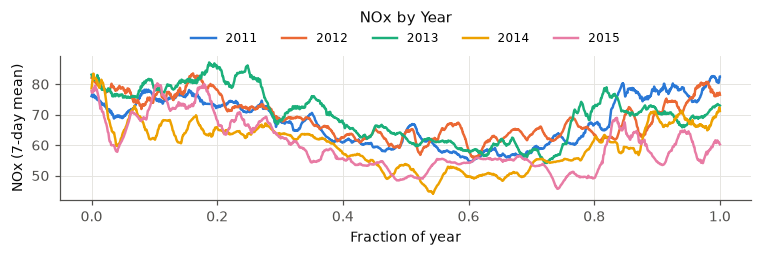

Annual mean NOX: year; 2011    67.68; 2012    68.79; 2013    70.01; 2014    60.08; 2015    59.89
2011: corr(AT,NOX) -0.674
2012: corr(AT,NOX) -0.567
2013: corr(AT,NOX) -0.582
2014: corr(AT,NOX) -0.656
2015: corr(AT,NOX) -0.594


In [9]:
fig, ax = plt.subplots(figsize=(7.0, 2.4))
for y, d in df.groupby("year"):
    roll = d.NOX.rolling(168, center=True, min_periods=24).mean()
    ax.plot(d.row_in_year / d.row_in_year.max(), roll, color=YEAR_COLORS[y], lw=1.6, label=str(y))
ax.set(xlabel="Fraction of year", ylabel="NOx (7-day mean)")
ax.set_title("NOx by Year", pad=22)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
save(fig, "fig6_nox_seasonal_by_year.png")

note("Annual mean NOX: " + df.groupby("year").NOX.mean().round(2).to_string().replace("\n", "; "))
for y, d in df.groupby("year"):
    note(f"{y}: corr(AT,NOX) {d.AT.corr(d.NOX):.3f}")

## 10. Other facts quoted in the report
Saturation, sensor-resolution, outlier and stuck-sensor checks.

In [10]:
note(f"AH>100: {(df.AH > 100).sum()} rows, max {df.AH.max()}")
note(f"TAT within 1 °C of max ({df.TAT.max():.2f}): {(df.TAT >= df.TAT.max() - 1).mean():.1%}")
note(f"TIT within 1 °C of max ({df.TIT.max():.1f}): {(df.TIT >= df.TIT.max() - 1).mean():.1%}")
note(f"TIT unique values {df.TIT.nunique()}, 0.1 °C resolution: "
     f"{np.allclose(df.TIT * 10, np.round(df.TIT * 10))}")
for xs in (["TAT", "TEY"], ["TAT", "CDP"]):
    r2 = sm.OLS(df.TIT, sm.add_constant(df[xs])).fit().rsquared
    note(f"R2 of TIT ~ {' + '.join(xs)}: {r2:.4f}")

z = (df[cols] - df[cols].mean()) / df[cols].std()
note("Rows with |z|>4 by column: " + (z.abs() > 4).sum().to_string().replace("\n", "; "))
note(f"CO min positive {df.CO.min():.5f}")

top = df.CO.value_counts()
stuck = df[df.CO == top.index[0]]
note(f"Most repeated CO value {top.index[0]} x{top.iloc[0]} "
     f"(years {sorted(stuck.year.unique().tolist())}, rows {stuck.row_in_year.min()}-{stuck.row_in_year.max()})")

AH>100: 478 rows, max 100.2
TAT within 1 °C of max (550.61): 63.9%
TIT within 1 °C of max (1100.9): 19.3%
TIT unique values 799, 0.1 °C resolution: True
R2 of TIT ~ TAT + TEY: 0.9367
R2 of TIT ~ TAT + CDP: 0.9612
Rows with |z|>4 by column: AT        0; AP        9; AH        0; AFDP      4; GTEP      0; TIT       9; TAT      49; CDP       0; TEY       0; CO      312; NOX     162
CO min positive 0.00039
Most repeated CO value 0.11124 x21 (years [2014], rows 55-99)
